In [1]:
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt
import Funciones as Funciones
from NNMF_GIF import NNMF_GIF 
from pathlib import Path
from ipyfilechooser import FileChooser
import ipywidgets as widgets
from IPython.display import  clear_output
import pandas as pd
#%config InlineBackend.figure_format = 'svg'
import librosa as lib

In [2]:
FC = FileChooser("G:\\Mi unidad\\Facultad\\Beca CIN\\NNMF-GIF\\Señales VPLAB")
FC.layout = widgets.Layout(width='1000px')
display(FC)

FileChooser(path='G:\Mi unidad\Facultad\Beca CIN\NNMF-GIF\Señales VPLAB', filename='', title='', show_hidden=F…

In [3]:
archivo = Path(FC.selected)
nombre_archivo = archivo.name
df = pd.read_csv(FC.selected, sep=',')

tiempos      = df['t_ms'].values
OVV_original = df['OVV'].values

fs_r        = 8000
filtro_pb            = 'Chebyshev II'
orden_filtro_pb      = 10
atenuacion_filtro_pb = 40
fc_filtro_pb         = 900
orden_filtro_pa      = 6
fc_filtro_pa         = 60
metrica = 1

OVV_original                   = OVV_original / max(abs(OVV_original))
OVV_filtrada_pb, b_pb, a_pb    = Funciones.LP_Filter(OVV_original, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
w_pb, h_pb                     = sig.freqz(b_pb, a_pb, fs=fs_r)
OVV_filtrada_pb_pa, b_pa, a_pa = Funciones.HP_Filter(OVV_filtrada_pb, fs=fs_r)

flujo_ovv_, br, ar, FF, BW1 = Funciones.IF_SNF_OneMetric(OVV_filtrada_pb_pa, fs=fs_r, numMetric=metrica)
flujo_ovv, br, ar, FF, BW1 = Funciones.IF_SNF_OneMetric(flujo_ovv_, fs=fs_r, numMetric=metrica,bw=250)

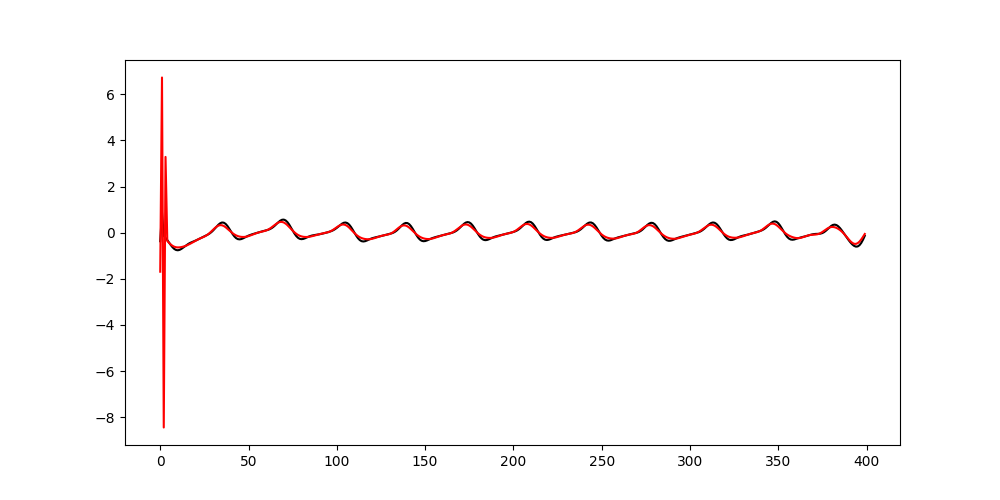

In [4]:
%matplotlib widget

fig,ax_ = plt.subplots(figsize=(10,5))
ax_.plot(flujo_ovv_,color='k')
ax_.plot(flujo_ovv,color='red');